---
# Cuaderno 1: Mutaciones en Cáncer
---
Author: Melissa Ormeño; Alexis Salas

Laboratory: Cancer Molecular Dynamics

Date: Mayo 2026

Aims:


In [15]:
import gzip
import io
import json
import pandas as pd
import requests
import matplotlib.pyplot as plt

## Extraer mutaciones desde el TCGA (maf file)

In [49]:


# 1. Genes de interés
lista_genes = ['BMPR1B', 'ACVR2A', 'BMPR1A', 'ACVR1B', 'TGFBR1', 'ACVRL1','TGFBR2', 'ACVR1', 'ACVR2B', 'BMPR2', 'AMHR2', 'ACVR1C']

# 2. Proyectos del GDC para tus tejidos de interés
proyectos_gdc = [
    "TCGA-BRCA",
    "TCGA-LUAD",
    "TCGA-LUSC",
    "TCGA-KIRC",
    "TCGA-KIRP",
    "TCGA-KICH",
    "TCGA-BLCA",
    "TCGA-COAD",
    "TCGA-READ",
    "TCGA-STAD",
    "TCGA-LGG",
    "TCGA-GBM",
    "TCGA-UCEC",
    "TCGA-UCS",
    "TCGA-OV",
    "TCGA-LIHC",
    "TCGA-PAAD",
    "TCGA-ESCA",
    "TCGA-THCA",
    "TCGA-SKCM",
    "TARGET-RT",
    "TARGET-WT",
]

ssm_endpt = "https://api.gdc.cancer.gov/ssms"
lista_mutaciones = []

print(
    f"Iniciando consulta directa a la base de datos de mutaciones para {len(lista_genes)} genes en {len(proyectos_gdc)} proyectos...\n"
)

# Iteramos proyecto por proyecto para evitar saturar la API
for idx, proyecto in enumerate(proyectos_gdc, 1):

    # Filtro de la base de datos: Queremos el gen X AND el proyecto Y
    filters = {
        "op": "and",
        "content": [
            {"op": "in", "content": {"field": "consequence.transcript.gene.symbol", "value": lista_genes}},
            {"op": "in", "content": {"field": "occurrence.case.project.project_id", "value": [proyecto]}},
        ],
    }

    # Campos exactos que me pediste extraer (Alelos, IDs, Aminoácidos, etc.)
    fields = [
        "ssm_id",
        "chromosome",
        "genomic_dna_change",  # Cambio nucleótido (HGVSc aproximado)
        "mutation_subtype",  # Tipo: SNP, INS, DEL
        "ncbi_build",
        "reference_allele",  # Alelo de Referencia
        "tumor_allele",  # Alelo Mutado
        "consequence.transcript.gene.symbol",
        "consequence.transcript.aa_change",  # Cambio Aminoácido (p.R432H)
        "consequence.transcript.hgvsp",  
        "consequence.transcript.annotation.vep_impact",
        "consequence.transcript.consequence_type",  # Efecto: missense, frameshift, etc.
        "occurrence.case.submitter_id",  # ID DEL PACIENTE (ej: TCGA-XX-XXXX)
        "occurrence.case.project.project_id",
    ]

    params = {
        "filters": json.dumps(filters),
        "fields": ",".join(fields),
        "format": "JSON",
        "size": "2000",  # Traer hasta 2000 mutaciones por proyecto (más que suficiente para un par de genes)
    }

    try:
        response = requests.get(ssm_endpt, params=params)
        data = response.json()
        hits = data.get("data", {}).get("hits", [])
    except Exception as e:
        print(f"   Error de conexión con el proyecto {proyecto}: {e}")
        continue

    if not hits:
        continue

    # Desempaquetamos la estructura JSON jerárquica del GDC a una tabla plana
    for hit in hits:
        gene_symbol = hit.get("consequence", [{}])[0].get("transcript", {}).get("gene", {}).get("symbol", "Unknown")
        aa_change = hit.get("consequence", [{}])[0].get("transcript", {}).get("aa_change", "p.?")
        transcript_info = hit.get("consequence", [{}])[0].get("transcript", {})
        aa_long = transcript_info.get("hgvsp", "p.?")
       
        # El formato MAF prefiere mayúsculas y guiones bajos (ej: Missense_Mutation en lugar de missense_variant)
        raw_efecto = hit.get("consequence", [{}])[0].get("transcript", {}).get("consequence_type", "Unknown")
        efecto_maf = raw_efecto.replace("_variant", "_Mutation").capitalize()
        if "missense" in raw_efecto:
            efecto_maf = "Missense_Mutation"
        elif "synonymous" in raw_efecto:
            efecto_maf = "Silent"
        elif "stop_gained" in raw_efecto:
            efecto_maf = "Nonsense_Mutation"
        # Un mismo cambio puede reportarse en múltiples muestras/pacientes de ese proyecto
        for occ in hit.get("occurrence", []):
            paciente_id = occ.get("case", {}).get("submitter_id", "Unknown")
            proj_id = occ.get("case", {}).get("project", {}).get("project_id", proyecto)

            registro = {
                "Patient_ID": paciente_id,
                "Tumor_Sample_Barcode": f"{paciente_id}-TUMOR", # ID de muestra aproximado
                "Hugo_Symbol": gene_symbol,
                "Chromosome": hit.get("chromosome"),
                "Variant_Classification": efecto_maf,
                "Variant_Type": hit.get("mutation_subtype"),
                "Reference_Allele": hit.get("reference_allele"),
                "Tumor_Seq_Allele2": hit.get("tumor_allele"),
                "HGVSc": hit.get("genomic_dna_change"),
                "HGVSp_Short": aa_change,
                "HGVSp": aa_long,  
                "Project_ID": proj_id,
            }
            lista_mutaciones.append(registro)

# DataFrame final
maf_genes = pd.DataFrame(lista_mutaciones)

# Mapear cancer
cancer_tejidos = {
    "TCGA-BRCA": "Breast",
    "TCGA-LUAD": "Bronchus and lung",
    "TCGA-LUSC": "Bronchus and lung",
    "TCGA-KIRC": "Kidney",
    "TCGA-KIRP": "Kidney",
    "TCGA-KICH": "Kidney",
    "TCGA-BLCA": "Bladder",
    "TCGA-COAD": "Colon",
    "TCGA-READ": "Rectum",
    "TCGA-STAD": "Stomach",
    "TCGA-LGG":  "Brain",
    "TCGA-GBM":  "Brain",
    "TCGA-UCEC": "Uterus",
    "TCGA-UCS":  "Uterus",
    "TCGA-OV":   "Ovary",
    "TCGA-LIHC": "Liver and intrahepatic bile ducts",
    "TCGA-PAAD": "Pancreas",
    "TCGA-ESCA": "Esophagus",
    "TCGA-THCA": "Thyroid gland",
    "TCGA-SKCM": "Skin",
    "TARGET-RT": "Kidney",
    "TARGET-WT": "Kidney"
}
maf_genes["cancer_type"] = maf_genes["Project_ID"].map(cancer_tejidos)

#Eliminar muatciones silent 
maf_genes = maf_genes.loc[~(maf_genes["Variant_Classification"]=="Silent")]

maf_genes = maf_genes.dropna(subset="cancer_type")
maf_genes = maf_genes.dropna(subset="HGVSp_Short")
print("Completado")

# Guardar a CSV inmediatamente
file_path = "../data/TCGA/mutaciones_TCGA.csv"
maf_genes.to_csv(file_path, index=False)
print(f"Archivo guardado en: {file_path}")
print(f"Patient count: {maf_genes["Patient_ID"].nunique()}")
print(f"Mutation count: {maf_genes["HGVSp_Short"].nunique()}")
maf_genes

Iniciando consulta directa a la base de datos de mutaciones para 12 genes en 22 proyectos...

Completado
Archivo guardado en: ../data/TCGA/mutaciones_TCGA.csv
Patient count: 860
Mutation count: 766


,Patient_ID,Tumor_Sample_Barcode,Hugo_Symbol,Chromosome,Variant_Classification,Variant_Type,Reference_Allele,Tumor_Seq_Allele2,HGVSc,HGVSp_Short,HGVSp,Project_ID,cancer_type
0,TCGA-A6-6781,TCGA-A6-6781-TUMOR,ACVR2A,chr2,Frameshift_mutation,Small deletion,A,-,chr2:g.147926117delA,K437Rfs*5,p.?,TCGA-COAD,Colon
1,TCGA-A5-A2K3,TCGA-A5-A2K3-TUMOR,ACVR2A,chr2,Frameshift_mutation,Small deletion,A,-,chr2:g.147926117delA,K437Rfs*5,p.?,TCGA-UCEC,Uterus
3,TCGA-CG-4306,TCGA-CG-4306-TUMOR,ACVR2A,chr2,Frameshift_mutation,Small deletion,A,-,chr2:g.147926117delA,K437Rfs*5,p.?,TCGA-STAD,Stomach
5,TCGA-QG-A5Z2,TCGA-QG-A5Z2-TUMOR,ACVR2A,chr2,Frameshift_mutation,Small deletion,A,-,chr2:g.147926117delA,K437Rfs*5,p.?,TCGA-COAD,Colon
6,TCGA-VQ-A91E,TCGA-VQ-A91E-TUMOR,ACVR2A,chr2,Frameshift_mutation,Small deletion,A,-,chr2:g.147926117delA,K437Rfs*5,p.?,TCGA-STAD,Stomach
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4058,TCGA-W3-A825,TCGA-W3-A825-TUMOR,ACVRL1,chr12,Downstream_gene_mutation,Single base substitution,G,A,chr12:g.51914537G>A,p.?,p.?,TCGA-SKCM,Skin
4059,TCGA-EE-A2MS,TCGA-EE-A2MS-TUMOR,TGFBR2,chr3,Non_coding_transcript_exon_mutation,Single base substitution,C,T,chr3:g.30691468C>T,p.?,p.?,TCGA-SKCM,Skin
4060,TCGA-ER-A193,TCGA-ER-A193-TUMOR,BMPR1A,chr10,Nonsense_Mutation,Single base substitution,C,T,chr10:g.86923702C>T,Q528*,p.?,TCGA-SKCM,Skin
4061,TCGA-D3-A1Q4,TCGA-D3-A1Q4-TUMOR,AMHR2,chr12,Missense_Mutation,Single base substitution,G,A,chr12:g.53425181G>A,M147I,p.?,TCGA-SKCM,Skin


## Graficos

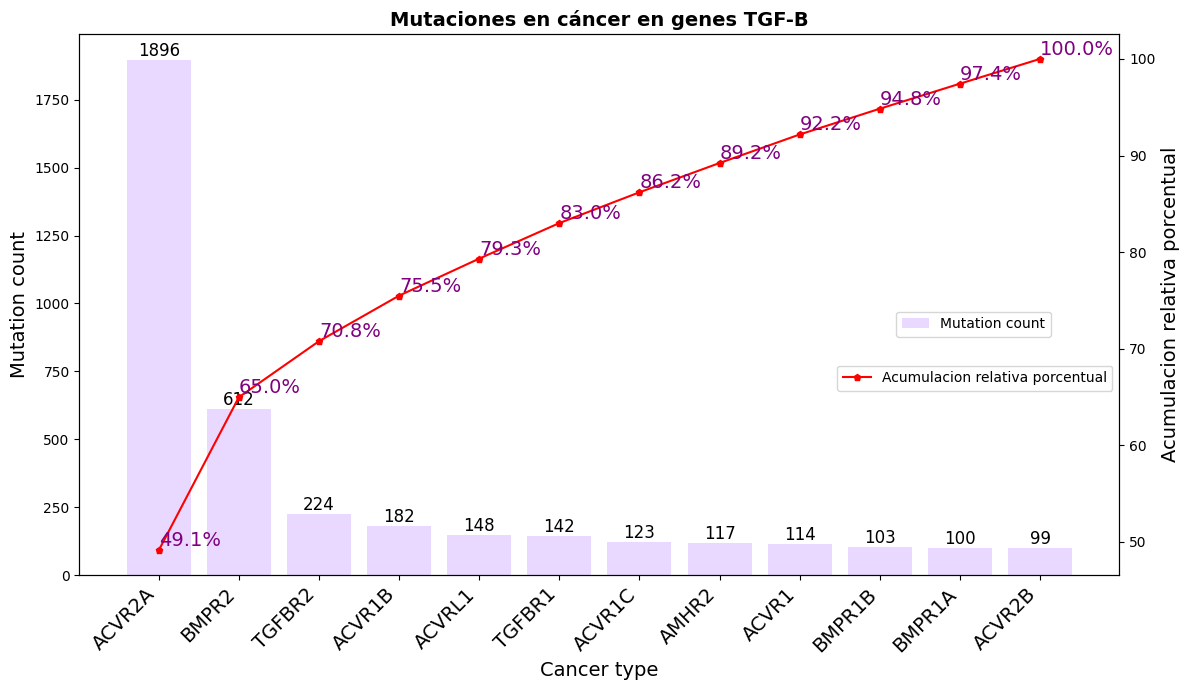

In [44]:
#PARAMETROS GENRALES
df = maf_genes #DATAFRAME A UTILIZAR
count = "HGVSp_Short" #COLUMNA QUE SE VA A CONTAR O SUMAR (eje Y)
grupo = "Hugo_Symbol" #barras
mutation_counts = df.groupby(grupo, as_index=False)[count].count() #OPERACION 

#PARAMETROS DE ETIQUETA
ylabel = 'Mutation count' # Etiqueta eje y
ylabel2 = 'Acumulacion relativa porcentual' # Etiqueta eje 2
set_title = 'Mutaciones en cáncer en genes TGF-B' # Titulo del grafico
set_xlabel = 'Cancer type' # Titulo eje X
leyenda_2 = 'Acumulacion relativa porcentual' # Nombre leyenda eje 2
leyenda_count = 'Mutation count' # Nombre leyenda eje 1

#PARAMETROS COLORES
color_bar = "#e9d8ffff"
color_linea = "red"
numero_acumulacion = 'purple'

#PARAMETRO DE GUARDADO
GUARDAR_GRAFICO = False
FORMATO_IMAGEN = "png"  # Cambiar a "svg" si se quiere otro formato (png y svg deben estar en minuscula)
DPI = 600  # Se usará solo si FORMATO_IMAGEN == "png"
NOMBRE_IMAGEN = "mut_missense_tgfb"
RUTA = f"../run/imagenes/{NOMBRE_IMAGEN}_.{FORMATO_IMAGEN}"


# Ordenar las mutaciones de mayor a menor
mutation_counts.sort_values(by=count, ascending=False, inplace=True)
mutation_counts.reset_index(drop=True, inplace=True)

# Calcular la acumulación relativa porcentual
mutation_counts['relativa_acum_porcentual'] = mutation_counts[count].cumsum() / mutation_counts[count].sum() * 100

# Crear la figura y los ejes
fig, ax = plt.subplots(figsize=(12, 7))  # Ajusta el tamaño de la figura

# Gráfico de barras para el número de mutaciones
bars = ax.bar(mutation_counts[grupo], mutation_counts[count])

# Gráfico de barras para la cantidad de mutaciones por tipo de cáncer
ax.bar(mutation_counts[grupo], mutation_counts[count], color=color_bar, label=leyenda_count)

# Crear un segundo eje y para la línea de acumulación relativa porcentual
ax2 = ax.twinx()
ax2.plot(mutation_counts.index, mutation_counts['relativa_acum_porcentual'], color=color_linea, marker="p", ms=5, label=leyenda_2)

# Agregar etiquetas con el número de mutaciones encima de las barras
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, height, f'{int(height)}', ha='center', va='bottom', color='black', fontsize=12)

# Agregar etiquetas con el porcentaje acumulado en los puntos de la línea
for i, value in enumerate(mutation_counts["relativa_acum_porcentual"]):
    ax2.text(i, value, f'{value:.1f}%', ha='left', va='bottom', color=numero_acumulacion, fontsize=14)
# Ajustar límites y etiquetas
ax.set_ylabel(ylabel, fontsize=14)
ax2.set_ylabel(ylabel2, fontsize=14)
ax.set_title(set_title, fontsize=14, fontweight = "bold")
ax.set_xlabel(set_xlabel, fontsize=14)

# Ajustar las etiquetas del eje x
ax.set_xticks(range(len(mutation_counts[grupo])))  # Colocar las etiquetas en las posiciones correctas
ax.set_xticklabels(mutation_counts[grupo], rotation=45, ha="right", fontsize=14)  # Rotar las etiquetas y alinearlas a la derecha

# Añadir leyendas
ax.legend(loc='best', bbox_to_anchor=(0.941, 0.5))  # Leyenda del primer eje
ax2.legend(loc='best', bbox_to_anchor=(1, 0.4))  # Leyenda del segundo eje, un poco más abajo

# Ajustar el diseño para evitar solapamientos
plt.tight_layout()

# Guardar el gráfico en formato SVG antes de mostrarlo
if GUARDAR_GRAFICO:
    if FORMATO_IMAGEN == "png":
        plt.savefig(RUTA, format="png", dpi=DPI)
    else:
        plt.savefig(RUTA, format=FORMATO_IMAGEN)

plt.show()

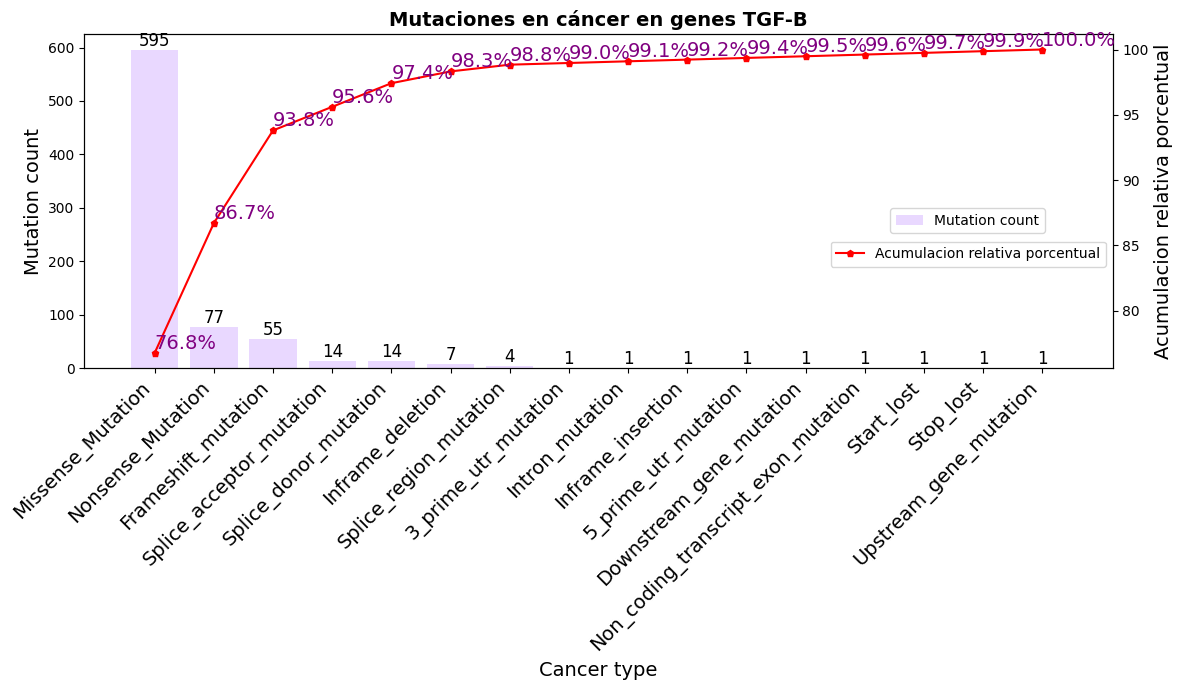

In [42]:
#PARAMETROS GENRALES
df = maf_genes #DATAFRAME A UTILIZAR
count = "HGVSp_Short" #COLUMNA QUE SE VA A CONTAR O SUMAR (eje Y)
grupo = "Variant_Classification" #barras
mutation_counts = df.groupby(grupo, as_index=False)[count].nunique() #OPERACION 

#PARAMETROS DE ETIQUETA
ylabel = 'Mutation count' # Etiqueta eje y
ylabel2 = 'Acumulacion relativa porcentual' # Etiqueta eje 2
set_title = 'Mutaciones en cáncer en genes TGF-B' # Titulo del grafico
set_xlabel = 'Cancer type' # Titulo eje X
leyenda_2 = 'Acumulacion relativa porcentual' # Nombre leyenda eje 2
leyenda_count = 'Mutation count' # Nombre leyenda eje 1

#PARAMETROS COLORES
color_bar = "#e9d8ffff"
color_linea = "red"
numero_acumulacion = 'purple'

#PARAMETRO DE GUARDADO
GUARDAR_GRAFICO = False
FORMATO_IMAGEN = "png"  # Cambiar a "svg" si se quiere otro formato (png y svg deben estar en minuscula)
DPI = 600  # Se usará solo si FORMATO_IMAGEN == "png"
NOMBRE_IMAGEN = "mut_missense_tgfb"
RUTA = f"../run/imagenes/{NOMBRE_IMAGEN}_.{FORMATO_IMAGEN}"


# Ordenar las mutaciones de mayor a menor
mutation_counts.sort_values(by=count, ascending=False, inplace=True)
mutation_counts.reset_index(drop=True, inplace=True)

# Calcular la acumulación relativa porcentual
mutation_counts['relativa_acum_porcentual'] = mutation_counts[count].cumsum() / mutation_counts[count].sum() * 100

# Crear la figura y los ejes
fig, ax = plt.subplots(figsize=(12, 7))  # Ajusta el tamaño de la figura

# Gráfico de barras para el número de mutaciones
bars = ax.bar(mutation_counts[grupo], mutation_counts[count])

# Gráfico de barras para la cantidad de mutaciones por tipo de cáncer
ax.bar(mutation_counts[grupo], mutation_counts[count], color=color_bar, label=leyenda_count)

# Crear un segundo eje y para la línea de acumulación relativa porcentual
ax2 = ax.twinx()
ax2.plot(mutation_counts.index, mutation_counts['relativa_acum_porcentual'], color=color_linea, marker="p", ms=5, label=leyenda_2)

# Agregar etiquetas con el número de mutaciones encima de las barras
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, height, f'{int(height)}', ha='center', va='bottom', color='black', fontsize=12)

# Agregar etiquetas con el porcentaje acumulado en los puntos de la línea
for i, value in enumerate(mutation_counts["relativa_acum_porcentual"]):
    ax2.text(i, value, f'{value:.1f}%', ha='left', va='bottom', color=numero_acumulacion, fontsize=14)
# Ajustar límites y etiquetas
ax.set_ylabel(ylabel, fontsize=14)
ax2.set_ylabel(ylabel2, fontsize=14)
ax.set_title(set_title, fontsize=14, fontweight = "bold")
ax.set_xlabel(set_xlabel, fontsize=14)

# Ajustar las etiquetas del eje x
ax.set_xticks(range(len(mutation_counts[grupo])))  # Colocar las etiquetas en las posiciones correctas
ax.set_xticklabels(mutation_counts[grupo], rotation=45, ha="right", fontsize=14)  # Rotar las etiquetas y alinearlas a la derecha

# Añadir leyendas
ax.legend(loc='best', bbox_to_anchor=(0.941, 0.5))  # Leyenda del primer eje
ax2.legend(loc='best', bbox_to_anchor=(1, 0.4))  # Leyenda del segundo eje, un poco más abajo

# Ajustar el diseño para evitar solapamientos
plt.tight_layout()

# Guardar el gráfico en formato SVG antes de mostrarlo
if GUARDAR_GRAFICO:
    if FORMATO_IMAGEN == "png":
        plt.savefig(RUTA, format="png", dpi=DPI)
    else:
        plt.savefig(RUTA, format=FORMATO_IMAGEN)

plt.show()

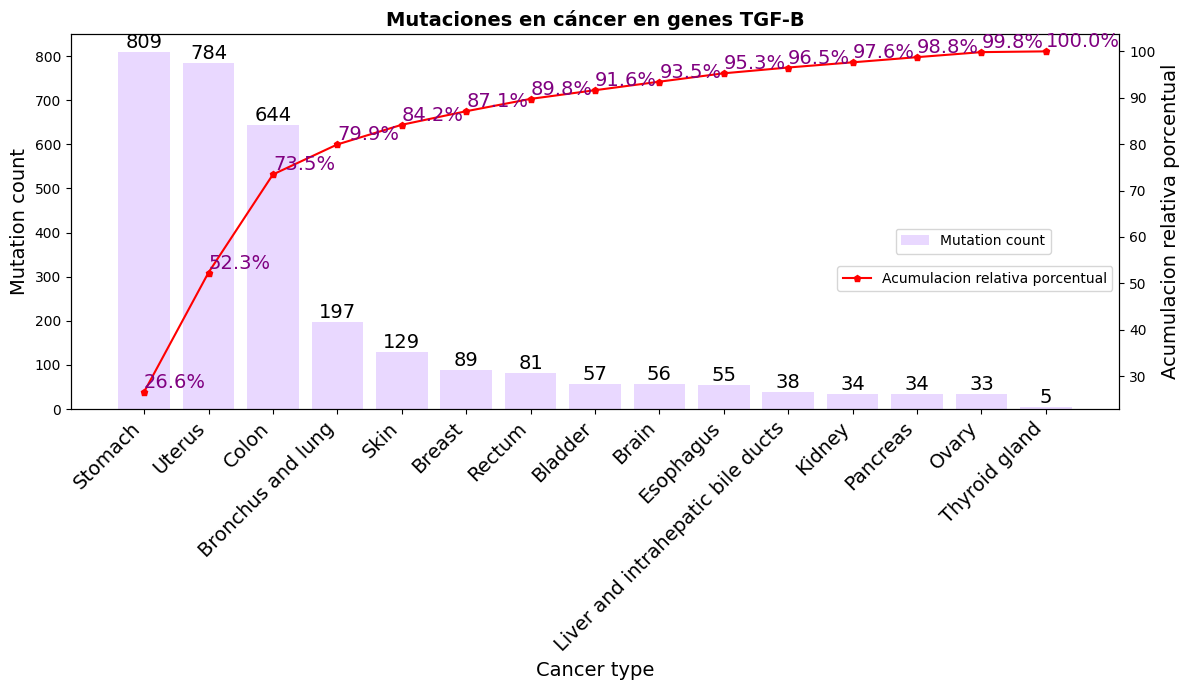

In [41]:
#PARAMETROS GENRALES
df = maf_genes #DATAFRAME A UTILIZAR
count = "HGVSp_Short" #COLUMNA QUE SE VA A CONTAR O SUMAR (eje Y)
grupo = "cancer_type" #barras
mutation_counts = df.groupby(grupo, as_index=False)[count].count() #OPERACION 

#PARAMETROS DE ETIQUETA
ylabel = 'Mutation count' # Etiqueta eje y
ylabel2 = 'Acumulacion relativa porcentual' # Etiqueta eje 2
set_title = 'Mutaciones en cáncer en genes TGF-B' # Titulo del grafico
set_xlabel = 'Cancer type' # Titulo eje X
leyenda_2 = 'Acumulacion relativa porcentual' # Nombre leyenda eje 2
leyenda_count = 'Mutation count' # Nombre leyenda eje 1

#PARAMETROS COLORES
color_bar = "#e9d8ffff"
color_linea = "red"
numero_acumulacion = 'purple'

#PARAMETRO DE GUARDADO
GUARDAR_GRAFICO = False
FORMATO_IMAGEN = "png"  # Cambiar a "svg" si se quiere otro formato (png y svg deben estar en minuscula)
DPI = 600  # Se usará solo si FORMATO_IMAGEN == "png"
NOMBRE_IMAGEN = "mut_missense_tgfb"
RUTA = f"../run/imagenes/{NOMBRE_IMAGEN}_.{FORMATO_IMAGEN}"


# Ordenar las mutaciones de mayor a menor
mutation_counts.sort_values(by=count, ascending=False, inplace=True)
mutation_counts.reset_index(drop=True, inplace=True)

# Calcular la acumulación relativa porcentual
mutation_counts['relativa_acum_porcentual'] = mutation_counts[count].cumsum() / mutation_counts[count].sum() * 100

# Crear la figura y los ejes
fig, ax = plt.subplots(figsize=(12, 7))  # Ajusta el tamaño de la figura

# Gráfico de barras para el número de mutaciones
bars = ax.bar(mutation_counts[grupo], mutation_counts[count])

# Gráfico de barras para la cantidad de mutaciones por tipo de cáncer
ax.bar(mutation_counts[grupo], mutation_counts[count], color=color_bar, label=leyenda_count)

# Crear un segundo eje y para la línea de acumulación relativa porcentual
ax2 = ax.twinx()
ax2.plot(mutation_counts.index, mutation_counts['relativa_acum_porcentual'], color=color_linea, marker="p", ms=5, label=leyenda_2)

# Agregar etiquetas con el número de mutaciones encima de las barras
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, height, f'{int(height)}', ha='center', va='bottom', color='black', fontsize=14)

# Agregar etiquetas con el porcentaje acumulado en los puntos de la línea
for i, value in enumerate(mutation_counts["relativa_acum_porcentual"]):
    ax2.text(i, value, f'{value:.1f}%', ha='left', va='bottom', color=numero_acumulacion, fontsize=14)
# Ajustar límites y etiquetas
ax.set_ylabel(ylabel, fontsize=14)
ax2.set_ylabel(ylabel2, fontsize=14)
ax.set_title(set_title, fontsize=14, fontweight = "bold")
ax.set_xlabel(set_xlabel, fontsize=14)

# Ajustar las etiquetas del eje x
ax.set_xticks(range(len(mutation_counts[grupo])))  # Colocar las etiquetas en las posiciones correctas
ax.set_xticklabels(mutation_counts[grupo], rotation=45, ha="right", fontsize=14)  # Rotar las etiquetas y alinearlas a la derecha

# Añadir leyendas
ax.legend(loc='best', bbox_to_anchor=(0.941, 0.5))  # Leyenda del primer eje
ax2.legend(loc='best', bbox_to_anchor=(1, 0.4))  # Leyenda del segundo eje, un poco más abajo

# Ajustar el diseño para evitar solapamientos
plt.tight_layout()

# Guardar el gráfico en formato SVG antes de mostrarlo
if GUARDAR_GRAFICO:
    if FORMATO_IMAGEN == "png":
        plt.savefig(RUTA, format="png", dpi=DPI)
    else:
        plt.savefig(RUTA, format=FORMATO_IMAGEN)

plt.show()